# Л3 — Рішення з ціною помилки

Модель класифікації дає ймовірність події, наприклад відмови обладнання. Щоб із цього вийшло рішення — висилати бригаду чи ні, — модель має вчитися на чесних даних, а поріг має враховувати ціну кожної помилки.

Ноутбук нижче проходить цей шлях на одній задачі, спрощено. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Intro to Machine Learning](https://www.kaggle.com/learn/intro-to-machine-learning) та [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning) з уроками про витік даних, pipelines і крос-валідацію.

Типовий шлях задачі класифікації (у дужках — кроки цього ноутбука):

- зрозуміти дані (1);
- перевірити, чи дані чесні: витік, зміщена вибірка, data drift (2–4);
- підготувати ознаки: кодування категорій, масштабування (5). У реальних проєктах ці перетворення збирають у pipeline, щоб до нових даних застосовувались ті самі кроки; тут вони написані вручну;
- розділити дані на навчальну й валідаційну частини (5). Часто замість однієї валідаційної частини беруть крос-валідацію; тут її немає;
- порівняти кілька моделей (6);
- підібрати гіперпараметри (7). Зазвичай це перебір за сіткою з крос-валідацією (`GridSearchCV`); тут лише одна крива для `alpha`;
- обрати поріг рішення під задачу (8);
- застосувати модель до нових даних (9) і далі стежити, чи не погіршилась вона з часом.

І головне: гарна метрика на валідації ще не гарантує, що модель працюватиме на нових даних. Якщо в даних є витік, зміщення чи зсув, модель виглядатиме добре, а рішення будуть поганими.

Інші часті проблеми даних, про які варто пам'ятати:

- **незбалансовані класи** — подія рідкісна, і частка правильних відповідей оманлива. Тут відмов 5–9%, тому моделі порівнюють за PR-AUC (крок 6);
- **замало даних** — модель запам'ятовує навчальні приклади замість закономірності; близьке явище видно на кривій перенавчання (крок 7);
- **пропуски й помилки в даних** — Л1;
- **помилки в мітках** — частину об'єктів позначено неправильно, і модель вчиться на цих помилках; тут цього немає;
- **зв'язок без причини** — ознака пов'язана з ціллю через третій чинник, а не напряму; Л2.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних, вартості й таблиця пасток — у `README.md`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

## 1. Завантаження даних

Спершу подивіться, що всередині файлів: розмірність, колонки, типи й частку відмов у `train`. Можуть допомогти `df.head()`, `df.shape` і `df.dtypes`.

Вартості свого варіанта впишіть із таблиці в `README.md`: від них залежить правило рішення в кроці 8.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

data_path = "/content/drive/MyDrive/IAD_Lab3"

COST_VISIT = 2750      # варіант 8
COST_FAILURE = 50000   # варіант 8

registry = pd.read_csv(f"{data_path}/registry.csv")
train = pd.read_csv(f"{data_path}/train.csv")
test = pd.read_csv(f"{data_path}/test.csv")

print("registry shape:", registry.shape)
print("train shape:", train.shape)
print("test shape:", test.shape)

failure_rate = train["failed"].mean()
print(f"Частка failed у train: {failure_rate:.4f} ({failure_rate * 100:.2f}%)")

display(train.head(3))

Mounted at /content/drive
registry shape: (6000, 8)
train shape: (4003, 20)
test shape: (1997, 19)
Частка failed у train: 0.0520 (5.20%)


,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,pd_stability,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,failed
0,EQ100001,38.967,4.411,0.8983,0.7987,17.924,1.477,17.920,70.862,13.442,0.8406,1.8185,0.4600,switchgear,kv10,centre,1987,2024,0,0
1,EQ100002,85.303,11.160,0.8843,0.7896,15.484,1.166,15.725,29.817,4.820,0.8608,0.3495,0.1815,transformer,kv10,centre,2002,2019,1,0
2,EQ100004,83.227,10.449,0.8885,0.8005,16.151,1.286,16.330,32.587,6.490,0.8339,0.3915,0.1941,transformer,kv10,south,2001,2025,0,0


## 2. Витік (M-1)

Витік (data leakage) — колонка, значення якої стає відомим лише після того, що ми хочемо передбачити. Наприклад, у даних про відмови може бути колонка «вартість ремонту». Вона дуже точно «передбачає» відмову: ремонтують саме те, що зламалося. Але вартість ремонту з'являється вже після відмови, а рішення ухвалюють раніше, коли об'єкт ще працює й цього значення немає. Модель, навчена на такій колонці, на навчальних даних виглядає чудово, а на нових об'єктах не працює. Такі колонки прибирають.

Не завжди відомо, коли заповнюють кожну колонку, тож витік шукають за ознакою «надто добре вгадує». Для кожної колонки окремо рахують **ROC AUC** — ймовірність того, що у випадкового об'єкта, який відмовив, значення колонки більше, ніж у випадкового справного. 0.5 — колонка не відрізняє їх зовсім, як підкидання монети; 1 — відрізняє ідеально. Звичайна ознака на кшталт температури чи навантаження так точно не вгадує. Колонку з AUC понад 0.9 тут вважають витоком. У реальному проєкті висока AUC — привід з'ясувати, коли колонку заповнюють.

1. Для кожної числової колонки `train`, крім `failed`, порахуйте `roc_auc_score(train["failed"], колонка)`. Якщо AUC менше 0.5, візьміть 1 − AUC: колонка пов'язана з відмовою навпаки, у тих, що відмовили, значення менші.
2. Виведіть AUC усіх колонок від більшого до меншого.
3. Колонки з AUC більше 0.9 приберіть із `train` і `test`.

Можуть допомогти `select_dtypes("number")`, `sort_values` і `drop(columns=...)`.

In [4]:
numeric_cols = train.select_dtypes(include=["number"]).columns.drop("failed")

auc_scores = {}
for col in numeric_cols:
    auc = roc_auc_score(train["failed"], train[col])
    auc_scores[col] = max(auc, 1 - auc)

auc_series = pd.Series(auc_scores).sort_values(ascending=False)
print("ROC AUC для числових колонок (відсортовано):")
print(auc_series.round(4))

leakage_cols = auc_series[auc_series > 0.9].index.tolist()
print(f"\nВиявлені колонки-витоки (AUC > 0.9): {leakage_cols}")

train = train.drop(columns=leakage_cols)
test = test.drop(columns=leakage_cols)
print(f"Форма train після вилучення витоку: {train.shape}")

ROC AUC для числових колонок (відсортовано):
temp_rise_median      0.7844
temp_rise_mean        0.7836
temp_rise_std         0.7834
pd_mean               0.7351
pd_std                0.7318
temp_per_load         0.6742
pd_per_load           0.6329
load_mean             0.6055
load_std              0.5968
install_year          0.5492
load_weekend_ratio    0.5285
outdoor               0.5251
last_overhaul_year    0.5197
pd_stability          0.5039
load_stability        0.5028
dtype: float64

Виявлені колонки-витоки (AUC > 0.9): []
Форма train після вилучення витоку: (4003, 20)


## 3. Зміщена вибірка (M-2)

Завжди треба враховувати, як збирали дані. Наприклад, лікарня має дані переважно про людей, які прийшли з підозрою на хворобу: здорові приходять туди набагато рідше. Тож хворих у таких даних набагато більше, ніж серед усіх людей. Таке зміщення вибірки (selection bias) буває й в інших задачах: результат відомий не для всіх об'єктів, а переважно для тих, що вже викликали підозру.

Модель на таких даних усе ще може навчитися відрізняти ризикові об'єкти від решти. Але числа, пораховані на зміщеній вибірці, — частку подій, точність, ефект рішення — не можна переносити на всі об'єкти: вони будуть спотворені.

У цій задачі `registry.csv` містить усі об'єкти, а `train.csv` — лише ті об'єкти `history`, для яких відомо, чи вони відмовили.

Поділіть кількість рядків `train` на кількість об'єктів `registry` з `cohort == "history"` і виведіть частку; менше 0.9 — вибірка зміщена. Тоді виведіть ще середній `install_year` об'єктів `history`, що є в `train`, і об'єктів `history`, яких у `train` немає. Може допомогти `isin`.

У коді після цього нічого не змінюється: рішення будується так само, але частку відмов і ефект на валідації не можна переносити на всі об'єкти.

In [5]:
history_registry = registry[registry["cohort"] == "history"]
total_history_count = len(history_registry)
train_count = len(train)

history_share = train_count / total_history_count
print(f"Частка об'єктів history у train: {history_share:.4f} ({history_share * 100:.2f}%)")

if history_share < 0.9:
    print("Вибірка є зміщеною (частка < 0.9).")
    in_train = history_registry["object_id"].isin(train["object_id"])
    mean_year_train = history_registry[in_train]["install_year"].mean()
    mean_year_not_train = history_registry[~in_train]["install_year"].mean()
    print(f"Середній install_year об'єктів у train: {mean_year_train:.2f}")
    print(f"Середній install_year об'єктів НЕ в train: {mean_year_not_train:.2f}")
else:
    print("Вибірка не є зміщеною.")

Частка об'єктів history у train: 1.0000 (100.00%)
Вибірка не є зміщеною.


## 4. Зсув у часі (M-3)

Властивості об'єктів змінюються з часом: люди старішають, обладнання зношується, датчик після калібрування чи заміни починає показувати інакше. Тому дані різних періодів можуть відрізнятися. Це називають **data drift** (зсув даних). Коли ж змінюється сам зв'язок ознак із ціллю, це **concept drift**; тут його немає.

Проблема виникає, коли зсув не врахували. Модель вивчила, що звичайна температура — 40 °C, а в нових даних датчик показує 45 °C для таких самих об'єктів. Модель побачить «гарячіші» об'єкти й помилятиметься, хоча нічого не змінилося.

**Як помітити:** порівняти розподіл ознак у навчальних і нових даних — середні, гістограми. Тут зсув середнього міряють у стандартних відхиленнях train: 0.5 — половина звичайного розкиду між об'єктами. Зсув рахують зі знаком: від'ємний означає, що в нових даних значення нижчі.

**Як боротися** — залежить від причини:

- **змінилася шкала вимірювання** (калібрування, інший датчик), а об'єкти ті самі — ознаки зводять до однієї шкали, наприклад стандартизують окремо в кожному періоді. Середнє стає 0, відхилення 1, а порядок об'єктів — хто гарячіший за кого — лишається;
- **змінилися самі об'єкти** — таке вирівнювання стерло б справжні зміни. Тоді модель перенавчають на свіжих даних і регулярно перевіряють її якість.

У цій задачі `train.csv` описує перший період, `test.csv` — другий. Якщо зсув є, він — у шкалі температурного датчика, тож підходить перший спосіб.

1. Виведіть зсув зі знаком: (середнє `temp_rise_mean` у test − середнє в train) / стандартне відхилення `temp_rise_mean` у train. Відхилення — `.std()` з pandas.
2. Якщо зсув більший за 0.5, стандартизуйте колонки `temp`: у train — середнім і відхиленням train, у test — середнім і відхиленням test. Якщо стандартизувати test за train, зсув лишиться.

In [6]:
temp = ["temp_rise_mean", "temp_rise_std", "temp_rise_median", "temp_per_load"]

mean_test = test["temp_rise_mean"].mean()
mean_train = train["temp_rise_mean"].mean()
std_train = train["temp_rise_mean"].std()

shift = (mean_test - mean_train) / std_train
print(f"Зсув температурного датчика (у стандартних відхиленнях train): {shift:.4f}")

if abs(shift) > 0.5:
    print("Виявлено зсув > 0.5. Стандартизуємо колонки temp окремо для train і test.")
    for col in temp:
        train[col] = (train[col] - train[col].mean()) / train[col].std()
        test[col] = (test[col] - test[col].mean()) / test[col].std()
else:
    print("Зсув у межах норми (<= 0.5). Додаткова стандартизація не потрібна.")

Зсув температурного датчика (у стандартних відхиленнях train): 0.9639
Виявлено зсув > 0.5. Стандартизуємо колонки temp окремо для train і test.


## 5. Ознаки й поділ

Моделі працюють із числами, тому категорійні колонки кодують **one-hot**: окрема колонка 0/1 на кожне значення. Порядкових номерів категоріям не дають, бо `north` не «більше» за `south`.

**Валідаційна частина.** Щоб зрозуміти, як модель працюватиме на нових об'єктах, її перевіряють на даних, яких вона не бачила під час навчання. Для цього частину `train` відкладають убік — це валідаційна частина. На ній і порівнюють моделі: модель, що просто запам'ятала навчальні об'єкти, на навчальних даних виглядатиме ідеально, а на валідаційних — ні.

Валідаційна частина має бути схожою на дані, до яких модель застосовуватимуть. Відмови рідкісні, тож при випадковому поділі частка відмов у ній може помітно відрізнятися від навчальної, а в малому наборі даних відмов там може не виявитися зовсім, і оцінити модель стане неможливо. `stratify=y` зберігає однакову частку відмов в обох частинах.

**Масштабування.** Ознаки мають різні одиниці й розміри: `load_mean` — від 15 до 148 А, а `load_stability` — від 0.85 до 0.91. Метод опорних векторів, найближчі сусіди й перцептрон рахують відстані чи зважені суми, тож для них різниця навантаження в 100 переважить різницю стабільності в 0.05, навіть якщо стабільність важливіша. Тому ознаки стандартизують: середнє 0, стандартне відхилення 1. Дереву рішень і наївному Баєсу масштаб не заважає. Середні й відхилення беруть лише з навчальної частини: якщо взяти їх з усіх даних, валідаційна частина вплине на навчання — це теж витік, як у кроці 2.

1. Зберіть ознаки через `pd.get_dummies(..., columns=categorical, dtype=float)`: `X` — з `train` без `object_id` і `failed`, `X_test` — з `test` без `object_id`. Колонки `X_test` мають іти в тому самому порядку, що в `X`: `X_test[X.columns]`.
2. `y` — колонка `failed`.
3. Поділ і стандартизацію задано нижче: `StandardScaler` навчається лише на `X_tr` і тим самим перетворенням застосовується до `X_va` і `X_test`.

In [7]:
categorical = ["equipment_type", "voltage_class", "region"]

train_encoded = pd.get_dummies(train.drop(columns=["object_id", "failed"]), columns=categorical, dtype=float)
test_encoded = pd.get_dummies(test.drop(columns=["object_id"]), columns=categorical, dtype=float)

# Узгодження колонок
X = train_encoded
X_test = test_encoded[X.columns]
y = train["failed"]

# Стратифікований поділ 75% / 25%
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

# Масштабування ознак
scaler = StandardScaler().fit(X_tr)
X_tr = scaler.transform(X_tr)
X_va = scaler.transform(X_va)
X_te = scaler.transform(X_test)

print(f"Розміри: X_tr = {X_tr.shape}, X_va = {X_va.shape}, X_te = {X_te.shape}")

Розміри: X_tr = (3002, 25), X_va = (1001, 25), X_te = (1997, 25)


## 6. П'ять моделей

**Як порівнювати.** Звична метрика — **accuracy**, частка правильних відповідей. При рідкісних подіях вона оманлива: якщо відмов 8%, модель, яка завжди каже «не відмовить», має accuracy 92%, але не знаходить жодної відмови.

Тому тут порівнюють інакше. Модель упорядковує об'єкти від найризикованішого до найспокійнішого. Якщо брати об'єкти згори списку, можна рахувати **precision** — яка частка взятих справді відмовила, і **recall** — яку частку всіх відмов уже знайдено. **PR-AUC** (`average_precision_score`) — середня precision, поки список росте від першої знайденої відмови до останньої. 1 — усі відмови стоять на самому верху списку; якщо порядок випадковий, PR-AUC дорівнює частці відмов. Тому PR-AUC завжди порівнюють із часткою відмов.

| Модель | Як оцінює ймовірність відмови |
|---|---|
| дерево рішень | ділить об'єкти порогами ознак; ймовірність — частка відмов у листку. `max_depth` обмежує кількість поділів |
| метод опорних векторів | шукає межу з найширшим проміжком між класами; сам дає лише відстань до межі, а `CalibratedClassifierCV` перетворює її на ймовірність |
| найближчі сусіди | частка відмов серед `n_neighbors` найближчих об'єктів навчальної частини |
| наївний Баєс | формула Баєса за припущення, що ознаки незалежні |
| багатошаровий перцептрон | прихований шар із 32 нейронів: кожен зважує ознаки й пропускає суму через функцію активації ReLU; вихідний нейрон дає ймовірність. Ваги підбирає зворотне поширення помилки, `alpha` — штраф за великі ваги |

Якщо навчальна PR-AUC набагато вища за валідаційну, модель запам'ятала навчальні об'єкти, а не навчилася розпізнавати ризик. Це **перенавчання** (overfitting), про нього — крок 7.

Далі рішення ухвалює перцептрон: на ньому в кроці 7 показано перенавчання, і рецепт однаковий для всіх варіантів. На ваших даних інша модель може бути кращою — це нормально, у звіті просто назвіть її. У реальному проєкті для рішення взяли б найкращу модель на валідації.

1. Навчіть кожну модель зі словника `models` на `X_tr`, `y_tr` і виведіть таблицю: модель, PR-AUC на навчальній і на валідаційній частині. PR-AUC рахуйте за ймовірностями `predict_proba(...)[:, 1]`. Функція, що рахує PR-AUC моделі на обох частинах, знадобиться ще в кроці 7.
2. Виведіть частку відмов у `y_va`.
3. Знайдіть найкращу модель на валідаційній частині й порівняйте її PR-AUC і PR-AUC перцептрона з часткою відмов — це відповідь для питання 2 звіту.

In [8]:
models = {
    "дерево рішень": DecisionTreeClassifier(max_depth=5, random_state=0),
    "опорні вектори": CalibratedClassifierCV(SVC(), ensemble=False),
    "найближчі сусіди": KNeighborsClassifier(n_neighbors=25),
    "наївний Баєс": GaussianNB(),
    "перцептрон": MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=1000, random_state=0),
}

results = []

for name, model in models.items():
    model.fit(X_tr, y_tr)
    pred_tr = model.predict_proba(X_tr)[:, 1]
    pred_va = model.predict_proba(X_va)[:, 1]

    pr_auc_tr = average_precision_score(y_tr, pred_tr)
    pr_auc_va = average_precision_score(y_va, pred_va)

    results.append({
        "Модель": name,
        "PR-AUC (train)": pr_auc_tr,
        "PR-AUC (val)": pr_auc_va
    })

results_df = pd.DataFrame(results)
print("Результати порівняння моделей:")
display(results_df.round(4))

val_failure_rate = y_va.mean()
print(f"Частка відмов у валідаційній вибірці (базовий PR-AUC): {val_failure_rate:.4f}")

Результати порівняння моделей:


,Модель,PR-AUC (train),PR-AUC (val)
0,дерево рішень,0.3791,0.1640
1,опорні вектори,0.9410,0.2058
2,найближчі сусіди,0.2357,0.2355
3,наївний Баєс,0.1969,0.2919
4,перцептрон,0.2357,0.2915


Частка відмов у валідаційній вибірці (базовий PR-AUC): 0.0519


## 7. Перенавчання перцептрона

**Перенавчання** — модель запам'ятовує навчальні приклади разом із їхнім шумом, замість того щоб знайти загальну закономірність. Як студент, що завчив відповіді до конкретних білетів: на цих білетах — відмінно, на нових — погано. Ознака перенавчання: навчальна метрика висока, валідаційна — значно нижча.

Один зі способів боротьби — **регуляризація**: штраф, що змушує модель бути простішою. У перцептрона це `alpha` — штраф за великі ваги. Із малим `alpha` мережа підлаштовує ваги під кожен навчальний об'єкт, і її ймовірності стають надто впевненими, близькими до 0 або 1. Правилу з кроку 8 потрібні правдоподібні ймовірності, тому для рішення взято `alpha=1`. У реальному проєкті `alpha` підбирали б перебором (див. вступ).

Якщо при малих `alpha` з'явиться попередження `ConvergenceWarning`, воно означає, що оптимізатор не встиг зійтися за `max_iter` ітерацій: мережа все ще підганяється під навчальні об'єкти.

1. Для кожного `alpha` зі списку навчіть такий самий перцептрон, як у кроці 6, але з цим `alpha`. Перцептрон із кроку 6 не перезаписуйте: він потрібен у кроках 8–9.
2. Виведіть таблицю «alpha, PR-AUC на навчальній і на валідаційній частині» і побудуйте обидві криві на одному графіку; вісь `alpha` — логарифмічна (`plt.xscale("log")`).
3. Прочитайте криву: що відбувається з навчальною і валідаційною PR-AUC, коли `alpha` зменшується, і при якому `alpha` розрив найбільший — це відповідь для питання 2 звіту.

Вплив регуляризації alpha на перенавчання перцептрона:


,alpha,PR-AUC (train),PR-AUC (val),Gap (tr - va)
0,0.0001,0.3765,0.2077,0.1688
1,0.0010,0.3756,0.2090,0.1667
2,0.0100,0.3661,0.2115,0.1546
3,0.1000,0.3101,0.2539,0.0561
4,1.0000,0.2357,0.2915,-0.0558


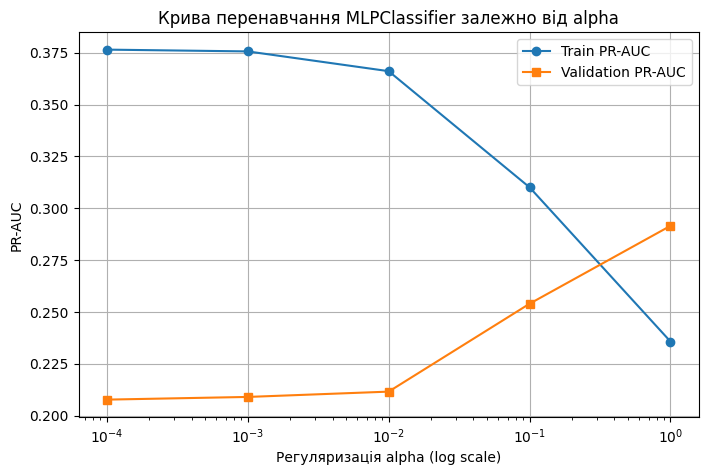

In [9]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]

# TODO: таблиця й графік PR-AUC від alpha
mlp_results = []

for a in alphas:
    mlp = MLPClassifier(hidden_layer_sizes=(32,), alpha=a, max_iter=1000, random_state=0)
    mlp.fit(X_tr, y_tr)

    p_tr = mlp.predict_proba(X_tr)[:, 1]
    p_va = mlp.predict_proba(X_va)[:, 1]

    score_tr = average_precision_score(y_tr, p_tr)
    score_va = average_precision_score(y_va, p_va)

    mlp_results.append({
        "alpha": a,
        "PR-AUC (train)": score_tr,
        "PR-AUC (val)": score_va,
        "Gap (tr - va)": score_tr - score_va
    })

mlp_df = pd.DataFrame(mlp_results)
print("Вплив регуляризації alpha на перенавчання перцептрона:")
display(mlp_df.round(4))

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(mlp_df["alpha"], mlp_df["PR-AUC (train)"], marker="o", label="Train PR-AUC")
plt.plot(mlp_df["alpha"], mlp_df["PR-AUC (val)"], marker="s", label="Validation PR-AUC")
plt.xscale("log")
plt.xlabel("Регуляризація alpha (log scale)")
plt.ylabel("PR-AUC")
plt.title("Крива перенавчання MLPClassifier залежно від alpha")
plt.grid(True)
plt.legend()
plt.show()

## 8. Правило рішення

Модель дає ймовірність, а диспетчер має вирішити «їхати чи ні». Звичний поріг 0.5 означає «їхати, якщо відмова ймовірніша, ніж її відсутність». Але помилки коштують по-різному: зайвий виїзд — `COST_VISIT`, пропущена відмова — `COST_FAILURE`, у десятки разів дорожче. Тож виїзд виправданий і за значно меншої ймовірності.

Не поїхати до об'єкта з ймовірністю відмови p — у середньому втратити p · `COST_FAILURE`. Виїзд окупається, коли p · `COST_FAILURE` не менше за `COST_VISIT`, тобто коли p не менша за поріг `COST_VISIT / COST_FAILURE`.

Правило працює, лише якщо ймовірностям можна вірити: серед об'єктів з ймовірністю 0.1 має справді відмовляти близько 10%. Це називають **калібруванням** (calibration). Перша проста перевірка — середня ймовірність має бути близькою до частки відмов.

Ефект рішення — скільки гривень воно зберігає проти «нікого не перевіряти»:

- витрати «нікого не перевіряти» = кількість відмов · `COST_FAILURE`;
- витрати рішення = кількість виїздів · `COST_VISIT` + кількість об'єктів, що відмовили і до яких не виїхали, · `COST_FAILURE`;
- ефект = перше − друге.

1. Порахуйте поріг `COST_VISIT / COST_FAILURE` і ймовірності перцептрона з кроку 6 на `X_va`.
2. Виведіть поріг, середню ймовірність і частку відмов у `y_va`.
3. Виведіть таблицю для трьох правил — поріг з вартостей, поріг 0.5, перевірити всіх: скільки об'єктів на виїзд і ефект у гривнях. Ефект для трьох правил — одна функція від рішень, а не три копії формули. `y_va` після поділу має перемішаний індекс, тож рішення порівнюйте з `y_va.to_numpy()`.
4. Порівняйте три правила: яке зберігає найбільше і чому поріг 0.5 тут поганий — це відповідь для питання 3 звіту.

In [10]:
# TODO: поріг, ймовірності й таблиця трьох правил
threshold = COST_VISIT / COST_FAILURE
mlp_main = models["перцептрон"]
prob_va = mlp_main.predict_proba(X_va)[:, 1]

print(f"Поріг рішення (COST_VISIT / COST_FAILURE): {threshold:.5f}")
print(f"Середня передбачена ймовірність на валідації: {prob_va.mean():.4f}")
print(f"Фактична частка відмов на валідації: {val_failure_rate:.4f}")

y_va_arr = y_va.to_numpy()

# Функція підрахунку економічного ефекту
def calculate_effect(decisions):
    cost_no_action = y_va_arr.sum() * COST_FAILURE
    cost_action = decisions.sum() * COST_VISIT + ((y_va_arr == 1) & (decisions == 0)).sum() * COST_FAILURE
    return cost_no_action - cost_action

rules = {
    f"Поріг з вартостей ({threshold:.4f})": (prob_va >= threshold).astype(int),
    "Поріг 0.5": (prob_va >= 0.5).astype(int),
    "Перевірити всіх": np.ones_like(y_va_arr, dtype=int)
}

comparison = []
for rule_name, dec in rules.items():
    comparison.append({
        "Правило": rule_name,
        "Кількість виїздів": dec.sum(),
        "Частка виїздів": f"{dec.mean() * 100:.1f}%",
        "Ефект (грн)": calculate_effect(dec)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

Поріг рішення (COST_VISIT / COST_FAILURE): 0.05500
Середня передбачена ймовірність на валідації: 0.0544
Фактична частка відмов на валідації: 0.0519


,Правило,Кількість виїздів,Частка виїздів,Ефект (грн)
0,Поріг з вартостей (0.0550),292,29.2%,1097000
1,Поріг 0.5,0,0.0%,0
2,Перевірити всіх,1001,100.0%,-152750


## 9. Рішення й самоперевірка

Порахуйте ймовірності перцептрона з кроку 6 на `X_te` і рішення: 1, якщо ймовірність не менша за поріг з вартостей, інакше 0. Це рішення ви здаєте: викладач порахує, скільки гривень воно зберегло б на справжніх результатах об'єктів test.

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [11]:
# TODO: рішення для test
prob_te = mlp_main.predict_proba(X_te)[:, 1]
decision = (prob_te >= threshold).astype(int)

submission = pd.DataFrame({"object_id": test["object_id"], "decision": decision})

assert (COST_VISIT, COST_FAILURE) in [(1800, 60000), (2750, 50000), (4080, 48000), (5500, 50000)], "вартості — з таблиці README"
assert all(max(a, 1 - a) <= 0.9 for a in (roc_auc_score(y, X[c]) for c in X.columns)), "в ознаках лишилася колонка з AUC понад 0.9"
assert list(X_test.columns) == list(X.columns), "колонки X_test мають збігатися з X"
assert len(X_va) == int(np.ceil(len(train) * 0.25)), "валідаційна частина — 25% train"
assert np.allclose(np.mean(X_tr, axis=0), 0) and np.allclose(np.std(X_tr, axis=0), 1), "X_tr не стандартизовано"
assert len(submission) == len(test) and submission["object_id"].is_unique, "має бути рядок на кожен об'єкт test"
assert pd.api.types.is_integer_dtype(submission["decision"]) and submission["decision"].isin([0, 1]).all(), "decision — цілі 0 або 1, а не True/False"
assert 0.02 <= submission["decision"].mean() <= 0.9, "на виїзд менше 2% або більше 90% об'єктів: перевірте поріг"

submission.to_csv("submission.csv", index=False)
print("усе гаразд: на виїзд", int(submission["decision"].sum()), "з", len(submission))

from google.colab import files
files.download("submission.csv")

усе гаразд: на виїзд 572 з 1997


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>